# Task 1 — Time-series preprocessing, exploratory analysis, and forecasting

This notebook examines the household electric power consumption data, answers six analytical questions with a visualization and interpretation for each, and trains a forecasting model with a chronological hyperparameter comparison. Run from the project root. The input is `dataset/household_power_consumption.txt`; the final model and metadata are written under `models/`.

The raw data are one-minute readings. Modeling and time-based analyses use hourly means. Voltage and intensity enter the forecast model only as lagged features. The 24-hour rolling mean is shifted to exclude the prediction hour.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_ROOT = Path.cwd()
DATASET_PATH = PROJECT_ROOT / 'dataset' / 'household_power_consumption.txt'
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
if not DATASET_PATH.is_file():
    raise FileNotFoundError(f'Dataset not found: {DATASET_PATH}')
print(f'Dataset: {DATASET_PATH}')

Dataset: C:\Users\upremier\Documents\new procect\Formative1_Pipeline_For_Time_Series\dataset\household_power_consumption.txt


## A. Dataset understanding and preprocessing

The file uses `;` delimiters and `?` for missing measurements. Parse those markers as missing values, combine date and time, convert measurements to numeric, and resample the one-minute observations to hourly means. Linear interpolation fills remaining missing hourly values. This is useful for short gaps in a continuous sensor series because it maintains the time grid and avoids treating missing readings as zero. Long gaps should be interpreted cautiously because interpolation assumes a gradual change between observed endpoints.

In [2]:
raw = pd.read_csv(DATASET_PATH, sep=';', na_values=['?'], low_memory=False)
raw['Datetime'] = pd.to_datetime(raw['Date'] + ' ' + raw['Time'], format='%d/%m/%Y %H:%M:%S')
raw = raw.set_index('Datetime').drop(columns=['Date', 'Time']).sort_index()
for col in raw.columns:
    raw[col] = pd.to_numeric(raw[col], errors='coerce')

raw_missing = raw.isna().sum().rename('missing_count').to_frame()
raw_missing['missing_percent'] = (raw_missing['missing_count'] / len(raw) * 100).round(3)
raw_step_counts = raw.index.to_series().diff().dropna().value_counts()
most_common_step = raw_step_counts.index[0] if len(raw_step_counts) else pd.NaT
duplicate_timestamps = int(raw.index.duplicated().sum())

df_hourly = raw.resample('h').mean()
hourly_missing_before_fill = int(df_hourly.isna().sum().sum())
df_hourly = df_hourly.interpolate(method='linear')
hourly_missing_after_fill = int(df_hourly.isna().sum().sum())

print(f'Raw observations: {len(raw):,}')
print(f'Time range: {raw.index.min()} through {raw.index.max()}')
print(f'Most common raw interval: {most_common_step}')
print(f'Duplicate timestamps: {duplicate_timestamps:,}')
print(f'Hourly observations: {len(df_hourly):,}; frequency: 1 hour')
print(f'Hourly gaps before interpolation: {hourly_missing_before_fill:,}; remaining after: {hourly_missing_after_fill:,}')
print('Missing values by raw measurement:')
display(raw_missing)
print('Hourly numeric summary:')
display(df_hourly.describe().T.round(3))

Raw observations: 2,075,259
Time range: 2006-12-16 17:24:00 through 2010-11-26 21:02:00
Most common raw interval: 0 days 00:01:00
Duplicate timestamps: 0
Hourly observations: 34,589; frequency: 1 hour
Hourly gaps before interpolation: 2,947; remaining after: 0
Missing values by raw measurement:


,missing_count,missing_percent
Global_active_power,25979,1.252
Global_reactive_power,25979,1.252
Voltage,25979,1.252
Global_intensity,25979,1.252
Sub_metering_1,25979,1.252
Sub_metering_2,25979,1.252
Sub_metering_3,25979,1.252


Hourly numeric summary:


,count,mean,std,min,25%,50%,75%,max
Global_active_power,34589.0,1.092,0.896,0.124,0.343,0.807,1.578,6.561
Global_reactive_power,34589.0,0.124,0.067,0.000,0.078,0.107,0.149,0.774
Voltage,34589.0,240.828,3.003,225.834,239.175,240.975,242.688,251.902
Global_intensity,34589.0,4.631,3.750,0.503,1.520,3.437,6.600,28.383
Sub_metering_1,34589.0,1.123,3.535,0.000,0.000,0.000,0.000,48.367
Sub_metering_2,34589.0,1.292,4.171,0.000,0.000,0.333,0.650,46.433
Sub_metering_3,34589.0,6.446,7.332,0.000,0.650,1.667,14.067,21.550


### Distribution and data-quality interpretation

The tables above report the full numerical distribution (count, mean, standard deviation, quartiles, and range) after hourly aggregation, along with raw missing counts and percentages. The source resolution is determined from timestamp intervals rather than assumed from the file name. `?` values are treated as missing, and hourly means ignore missing minute readings. Remaining missing hourly values are linearly interpolated; the before/after counts make the amount of imputation visible. Interpolation is selected to retain a continuous hourly series for lag and rolling calculations, but can smooth extremes across gaps.

## B. Analytical questions

Each question has a plot and a data-driven interpretation printed from the series, so the conclusion can be reviewed alongside its evidence.

### Question 1 — Is average household power changing over the observed period?

The monthly mean shows long-term movement while the linear trend line summarizes its overall direction. This is a descriptive trend, not evidence that time itself causes consumption changes.

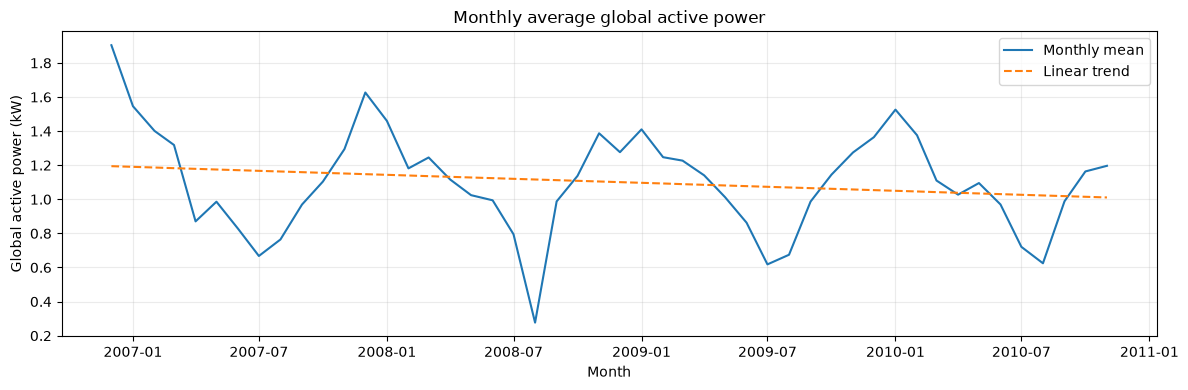

Interpretation: The fitted monthly trend is decreasing by 0.0039 kW per month. Monthly means range from 0.277 to 1.904 kW, showing that shorter-term variability is also present.


In [3]:
target = 'Global_active_power'
monthly_power = df_hourly[target].resample('MS').mean().dropna()
x = np.arange(len(monthly_power))
slope_per_month = np.polyfit(x, monthly_power.to_numpy(), 1)[0] if len(monthly_power) > 1 else 0.0
trend = np.polyval(np.polyfit(x, monthly_power.to_numpy(), 1), x) if len(monthly_power) > 1 else monthly_power.to_numpy()
plt.figure(figsize=(12, 4))
plt.plot(monthly_power.index, monthly_power, label='Monthly mean')
plt.plot(monthly_power.index, trend, '--', label='Linear trend')
plt.title('Monthly average global active power')
plt.ylabel('Global active power (kW)')
plt.xlabel('Month')
plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()
direction = 'increasing' if slope_per_month > 0 else 'decreasing' if slope_per_month < 0 else 'flat'
print(f'Interpretation: The fitted monthly trend is {direction} by {abs(slope_per_month):.4f} kW per month. Monthly means range from {monthly_power.min():.3f} to {monthly_power.max():.3f} kW, showing that shorter-term variability is also present.')

### Question 2 — At what time of day is average consumption highest and lowest?

The hourly profile averages each clock hour across all dates. A peak and trough that recur in this profile indicate a daily usage pattern.

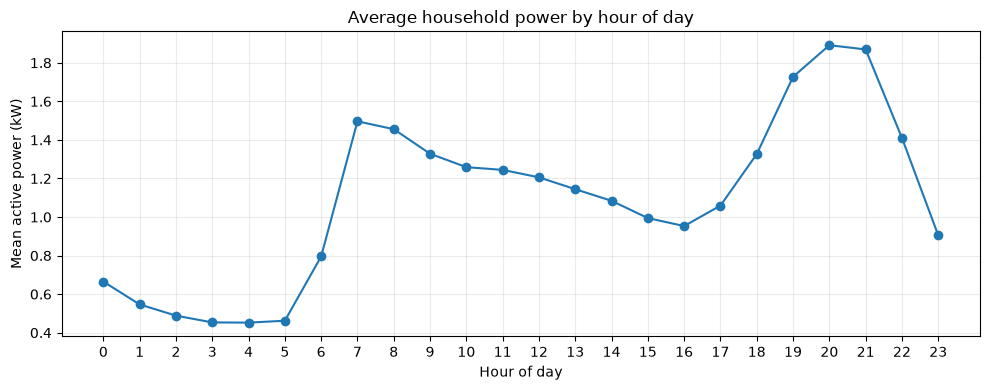

Interpretation: Mean demand peaks at 20:00 (1.891 kW) and is lowest at 04:00 (0.452 kW). The 1.439 kW gap is consistent with a strong within-day usage cycle.


In [4]:
hour_profile = df_hourly.groupby(df_hourly.index.hour)[target].mean()
peak_hour, trough_hour = int(hour_profile.idxmax()), int(hour_profile.idxmin())
plt.figure(figsize=(10, 4))
plt.plot(hour_profile.index, hour_profile.values, marker='o')
plt.xticks(range(24)); plt.xlabel('Hour of day'); plt.ylabel('Mean active power (kW)')
plt.title('Average household power by hour of day'); plt.grid(alpha=.25); plt.tight_layout(); plt.show()
print(f'Interpretation: Mean demand peaks at {peak_hour:02d}:00 ({hour_profile.max():.3f} kW) and is lowest at {trough_hour:02d}:00 ({hour_profile.min():.3f} kW). The {hour_profile.max()-hour_profile.min():.3f} kW gap is consistent with a strong within-day usage cycle.')

### Question 3 — How are voltage, intensity, and sub-meter readings associated with active power?

Correlations summarize linear co-movement. The plot is descriptive: an association does not establish causation, and global intensity is closely related by construction to active power.

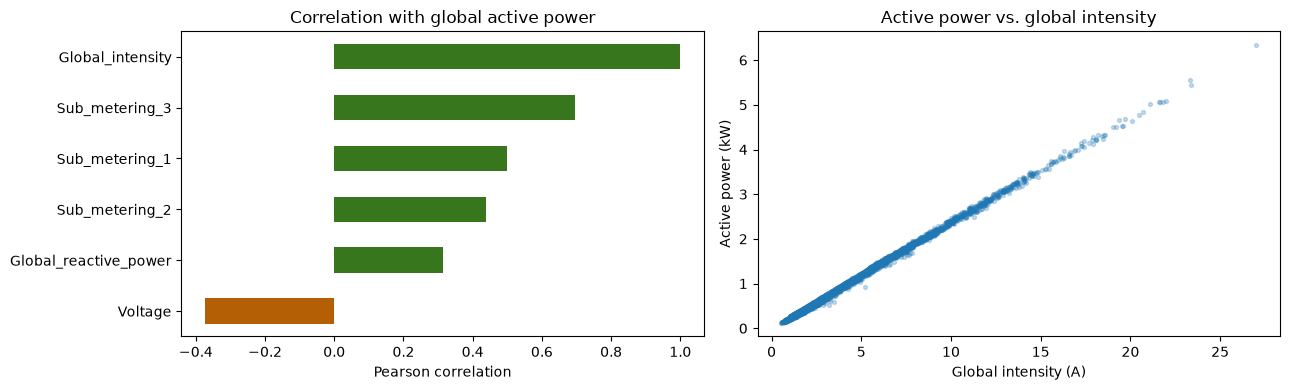

Interpretation: Global_intensity has the strongest absolute linear association with active power (r=0.999). Global intensity and sub-meter readings are contemporaneous descriptive measurements here; the forecasting model below uses only their lagged counterparts to avoid same-hour leakage.


In [5]:
external_columns = ['Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
power_corr = df_hourly[external_columns + [target]].corr(numeric_only=True)[target].drop(target).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
power_corr.plot(kind='barh', ax=axes[0], color=['#b45f06' if v < 0 else '#38761d' for v in power_corr])
axes[0].set_title('Correlation with global active power'); axes[0].set_xlabel('Pearson correlation')
sample = df_hourly.iloc[::max(1, len(df_hourly)//5000)]
axes[1].scatter(sample['Global_intensity'], sample[target], s=8, alpha=.25)
axes[1].set_title('Active power vs. global intensity'); axes[1].set_xlabel('Global intensity (A)'); axes[1].set_ylabel('Active power (kW)')
plt.tight_layout(); plt.show()
strongest_name, strongest_value = power_corr.abs().idxmax(), power_corr.loc[power_corr.abs().idxmax()]
print(f'Interpretation: {strongest_name} has the strongest absolute linear association with active power (r={strongest_value:.3f}). Global intensity and sub-meter readings are contemporaneous descriptive measurements here; the forecasting model below uses only their lagged counterparts to avoid same-hour leakage.')

### Question 4 — Does active power show lag effects at 1 hour, 24 hours, or 1 week?

Autocorrelation compares the series with its own past values. Strong correlation at 24 or 168 hours suggests daily or weekly repetition. These lag relationships motivate time-series features.

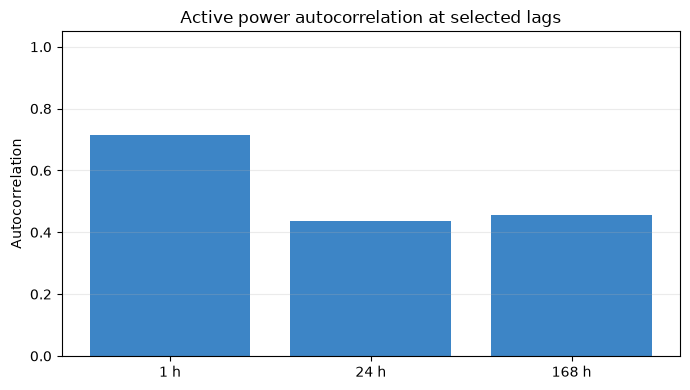

Interpretation: 1h lag r=0.716; 24h lag r=0.436; 168h lag r=0.455. The strongest tested relationship is at 1 hours, indicating that this past value is useful context for forecasting.


In [6]:
lags = [1, 24, 168]
lag_corr = pd.Series({lag: df_hourly[target].autocorr(lag=lag) for lag in lags}, name='autocorrelation')
plt.figure(figsize=(7, 4))
plt.bar([f'{lag} h' for lag in lags], lag_corr.values, color='#3d85c6')
plt.ylim(min(0, lag_corr.min() - .05), 1.05); plt.ylabel('Autocorrelation'); plt.title('Active power autocorrelation at selected lags')
plt.grid(axis='y', alpha=.25); plt.tight_layout(); plt.show()
best_lag = int(lag_corr.abs().idxmax())
print('Interpretation: ' + '; '.join(f'{lag}h lag r={value:.3f}' for lag, value in lag_corr.items()) + f'. The strongest tested relationship is at {best_lag} hours, indicating that this past value is useful context for forecasting.')

### Question 5 — Do moving averages reveal smoother daily and weekly consumption patterns?

The plot compares raw hourly demand with trailing 24-hour and 168-hour means over a representative four-week window. Trailing windows are shifted so each average uses completed hours only.

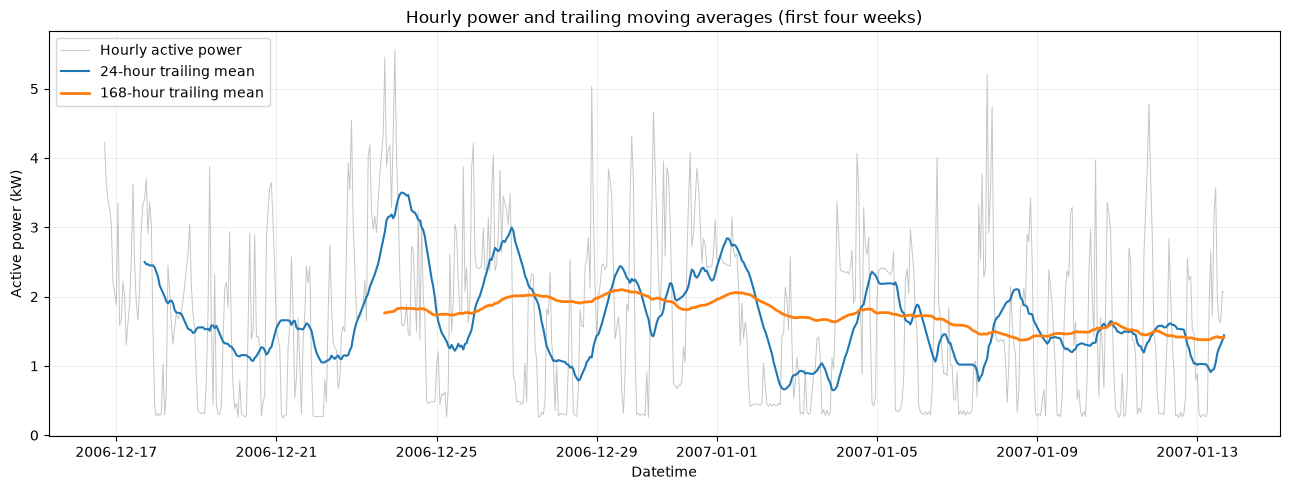

Interpretation: The 24-hour trailing mean correlates 0.361 with hourly power. Its standard deviation (0.425 kW) is below the hourly series (0.896 kW), demonstrating how averaging reduces short-term variation while retaining the broader level.


In [7]:
moving = df_hourly[[target]].copy()
moving['24-hour trailing mean'] = moving[target].rolling(24).mean().shift(1)
moving['168-hour trailing mean'] = moving[target].rolling(168).mean().shift(1)
window = moving.iloc[:24*28]
plt.figure(figsize=(13, 5))
plt.plot(window.index, window[target], color='gray', alpha=.45, linewidth=.7, label='Hourly active power')
plt.plot(window.index, window['24-hour trailing mean'], label='24-hour trailing mean', linewidth=1.5)
plt.plot(window.index, window['168-hour trailing mean'], label='168-hour trailing mean', linewidth=2)
plt.title('Hourly power and trailing moving averages (first four weeks)')
plt.ylabel('Active power (kW)'); plt.xlabel('Datetime'); plt.legend(); plt.grid(alpha=.2); plt.tight_layout(); plt.show()
daily_corr = moving[[target, '24-hour trailing mean']].dropna().corr().iloc[0, 1]
raw_std, smooth_std = moving[target].std(), moving['24-hour trailing mean'].std()
print(f'Interpretation: The 24-hour trailing mean correlates {daily_corr:.3f} with hourly power. Its standard deviation ({smooth_std:.3f} kW) is below the hourly series ({raw_std:.3f} kW), demonstrating how averaging reduces short-term variation while retaining the broader level.')

### Question 6 — Does the within-day profile differ between weekdays and weekends?

Comparing average hourly curves by day type highlights potential differences in household routines. This groups all calendar dates by weekday versus weekend.

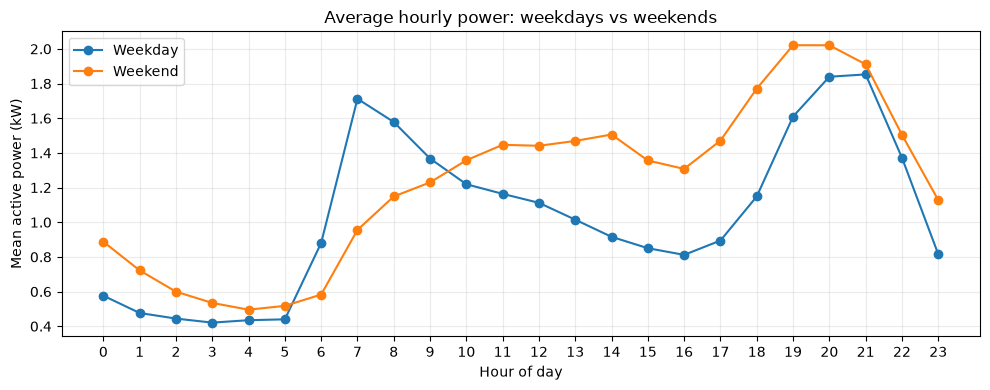

Interpretation: Mean hourly demand is 0.185 kW higher on weekends.
The plotted profiles show whether that difference is consistent through the day or concentrated in particular hours; averages alone do not identify the household activity causing it.


In [8]:
day_type = pd.Series(np.where(df_hourly.index.day_of_week >= 5, 'Weekend', 'Weekday'), index=df_hourly.index, name='day_type')
day_profile = df_hourly.groupby([day_type, df_hourly.index.hour])[target].mean().unstack(0)
plt.figure(figsize=(10, 4))
for label in day_profile.columns:
    plt.plot(day_profile.index, day_profile[label], marker='o', label=label)
plt.xticks(range(24)); plt.xlabel('Hour of day'); plt.ylabel('Mean active power (kW)')
plt.title('Average hourly power: weekdays vs weekends'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()
weekend_delta = day_profile['Weekend'].mean() - day_profile['Weekday'].mean()
print(f'Interpretation: Mean hourly demand is {abs(weekend_delta):.3f} kW higher on weekends.' if weekend_delta > 0 else f'Interpretation: Mean hourly demand is {abs(weekend_delta):.3f} kW lower on weekends.' if weekend_delta < 0 else 'Interpretation: Overall hourly means are equal across weekdays and weekends.')
print(f'The plotted profiles show whether that difference is consistent through the day or concentrated in particular hours; averages alone do not identify the household activity causing it.')

## C. Forecasting, hyperparameter comparison, and final model

Predict the next hourly `Global_active_power`. Inputs are all historical at the prediction timestamp: active power at 1 and 24 hours earlier, voltage and intensity one hour earlier, and the trailing 24-hour mean shifted by one hour. A chronological 80/20 split reserves the final 20% as a test period. Hyperparameters are compared on a validation segment taken from the first 80%; the final test period is not used to choose settings.

In [9]:
TARGET = 'Global_active_power'
feature_columns = ['power_lag_1h', 'power_lag_24h', 'voltage_lag_1h', 'intensity_lag_1h', 'rolling_mean_24h']
model_data = df_hourly.copy()
model_data['power_lag_1h'] = model_data[TARGET].shift(1)
model_data['power_lag_24h'] = model_data[TARGET].shift(24)
model_data['voltage_lag_1h'] = model_data['Voltage'].shift(1)
model_data['intensity_lag_1h'] = model_data['Global_intensity'].shift(1)
model_data['rolling_mean_24h'] = model_data[TARGET].rolling(24).mean().shift(1)
model_data = model_data.dropna(subset=feature_columns + [TARGET])
X, y = model_data[feature_columns], model_data[TARGET]
split = int(len(model_data) * 0.8)
X_dev, X_test = X.iloc[:split], X.iloc[split:]
y_dev, y_test = y.iloc[:split], y.iloc[split:]
validation_start = int(len(X_dev) * 0.8)
X_train, X_valid = X_dev.iloc[:validation_start], X_dev.iloc[validation_start:]
y_train, y_valid = y_dev.iloc[:validation_start], y_dev.iloc[validation_start:]
print(f'Development rows: {len(X_dev):,}; validation rows: {len(X_valid):,}; final test rows: {len(X_test):,}')
print(f'Train period: {X_train.index.min()} through {X_train.index.max()}')
print(f'Validation period: {X_valid.index.min()} through {X_valid.index.max()}')
print(f'Test period: {X_test.index.min()} through {X_test.index.max()}')

Development rows: 27,652; validation rows: 5,531; final test rows: 6,913
Train period: 2006-12-17 17:00:00 through 2009-06-26 09:00:00
Validation period: 2009-06-26 10:00:00 through 2010-02-11 20:00:00
Test period: 2010-02-11 21:00:00 through 2010-11-26 21:00:00


In [10]:
experiments = [
    {'name': 'RF-50-depth8', 'n_estimators': 50, 'max_depth': 8},
    {'name': 'RF-100-depth10', 'n_estimators': 100, 'max_depth': 10},
    {'name': 'RF-150-depth14', 'n_estimators': 150, 'max_depth': 14},
]
experiment_rows = []
fitted_candidates = {}
for settings in experiments:
    candidate = RandomForestRegressor(
        n_estimators=settings['n_estimators'],
        max_depth=settings['max_depth'],
        random_state=42,
        n_jobs=-1,
    )
    candidate.fit(X_train, y_train)
    valid_pred = candidate.predict(X_valid)
    experiment_rows.append({
        'experiment': settings['name'],
        'n_estimators': settings['n_estimators'],
        'max_depth': settings['max_depth'],
        'validation_RMSE': np.sqrt(mean_squared_error(y_valid, valid_pred)),
        'validation_MAE': mean_absolute_error(y_valid, valid_pred),
    })
    fitted_candidates[settings['name']] = candidate

experiment_table = pd.DataFrame(experiment_rows).sort_values('validation_RMSE').reset_index(drop=True)
display(experiment_table.round(4))
best_name = experiment_table.loc[0, 'experiment']
best_settings = next(item for item in experiments if item['name'] == best_name)
print(f"Interpretation: {best_name} has the lowest validation RMSE ({experiment_table.loc[0, 'validation_RMSE']:.4f}) among the tested settings and is selected for final evaluation. The validation period—not the final test period—determines this choice.")
experiment_table.to_csv(MODELS_DIR / 'model_experiments.csv', index=False)

,experiment,n_estimators,max_depth,validation_RMSE,validation_MAE
0,RF-50-depth8,50,8,0.5707,0.4003
1,RF-100-depth10,100,10,0.5723,0.4009
2,RF-150-depth14,150,14,0.5784,0.4067


Interpretation: RF-50-depth8 has the lowest validation RMSE (0.5707) among the tested settings and is selected for final evaluation. The validation period—not the final test period—determines this choice.


Final chronological test RMSE: 0.5138
Final chronological test MAE: 0.3628


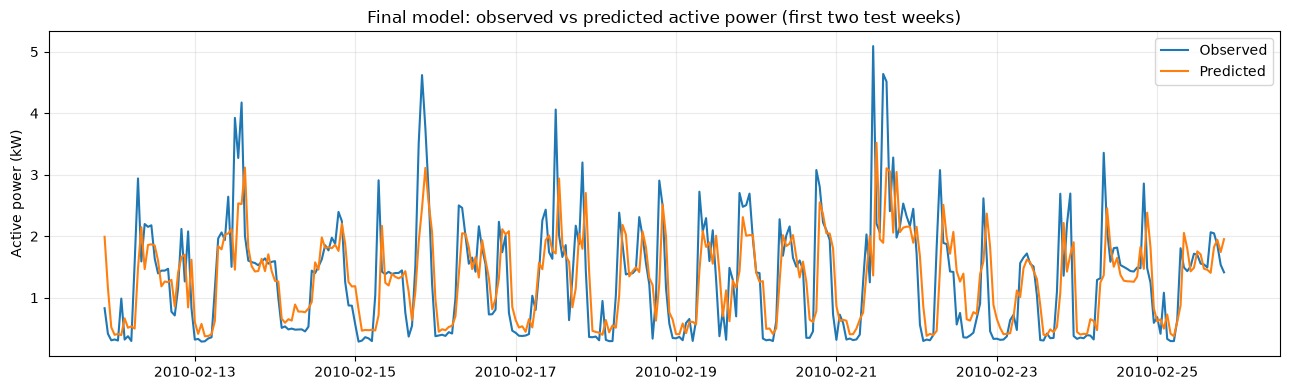

In [11]:
best_model = RandomForestRegressor(
    n_estimators=best_settings['n_estimators'],
    max_depth=best_settings['max_depth'],
    random_state=42,
    n_jobs=-1,
)
best_model.fit(X_dev, y_dev)
test_pred = best_model.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_mae = mean_absolute_error(y_test, test_pred)
print(f'Final chronological test RMSE: {test_rmse:.4f}')
print(f'Final chronological test MAE: {test_mae:.4f}')

plot_n = min(24 * 14, len(y_test))
plt.figure(figsize=(13, 4))
plt.plot(y_test.index[:plot_n], y_test.iloc[:plot_n], label='Observed')
plt.plot(y_test.index[:plot_n], test_pred[:plot_n], label='Predicted')
plt.title('Final model: observed vs predicted active power (first two test weeks)')
plt.ylabel('Active power (kW)'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

In [12]:
model_path = MODELS_DIR / 'model.joblib'
joblib.dump(best_model, model_path)
metadata = {
    'feature_names': feature_columns,
    'target': TARGET,
    'selected_experiment': best_name,
    'test_rmse': float(test_rmse),
    'test_mae': float(test_mae),
}
metadata_path = MODELS_DIR / 'model_metadata.json'
with metadata_path.open('w', encoding='utf-8') as file:
    json.dump(metadata, file, indent=4)
print(f'Model saved: {model_path}')
print(f'Feature metadata saved: {metadata_path}')
print(f'Validation experiment table saved: {MODELS_DIR / "model_experiments.csv"}')

Model saved: C:\Users\upremier\Documents\new procect\Formative1_Pipeline_For_Time_Series\models\model.joblib
Feature metadata saved: C:\Users\upremier\Documents\new procect\Formative1_Pipeline_For_Time_Series\models\model_metadata.json
Validation experiment table saved: C:\Users\upremier\Documents\new procect\Formative1_Pipeline_For_Time_Series\models\model_experiments.csv


## Summary

The dataset is a minute-level household electricity series summarized to hourly means for analysis. Missing `?` readings were treated as nulls; hourly aggregation ignored missing minute readings and linear interpolation filled residual hourly gaps. Six visual analyses examine long-run trend, time-of-day usage, external-variable associations, lag dependence, moving-average smoothing, and weekday/weekend profiles. The forecast comparison evaluates three Random Forest settings on a chronological validation segment, chooses the lowest validation RMSE, then reports final metrics once on a later held-out test period. The exported metadata records the exact ordered feature list for inference.